In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm.auto import tqdm

In [3]:
import mctpy as mct

In [4]:
from mctpy.structurefactors.oz import PY, HSS

In [5]:
rho = 1.0

In [6]:
Sq = mct.structurefactors.oz.Sq()
Sq.solve (closure=PY(), potential=HSS(), rho=rho, accuracy=1e-12, N=8192, use_ng=False)

(array([2.48916871e-01, 7.40332541e-01, 1.22421831e+00, ...,
        2.52649482e-10, 2.53609717e-10, 2.54098447e-10], shape=(8192,)),
 array([2.53538084e+00, 7.60178216e+00, 1.26551125e+01, ...,
        8.76056009e-05, 8.90005292e-05, 8.96979884e-05], shape=(8192,)))

In [7]:
Sq2 = mct.structurefactors.oz.Sq()
Sq2.solve (closure=PY(), potential=HSS(), rho=rho, accuracy=1e-12, N=8192, use_ng=True)

(array([2.48916871e-01, 7.40332541e-01, 1.22421831e+00, ...,
        2.52650513e-10, 2.53610653e-10, 2.54098944e-10], shape=(8192,)),
 array([2.53538084e+00, 7.60178216e+00, 1.26551125e+01, ...,
        8.76056009e-05, 8.90005292e-05, 8.96979884e-05], shape=(8192,)))

In [8]:
qgrid = np.linspace(0.2,39.8,100)
hspy = mct.structurefactors.hssPY(phi=rho*np.pi/6.)

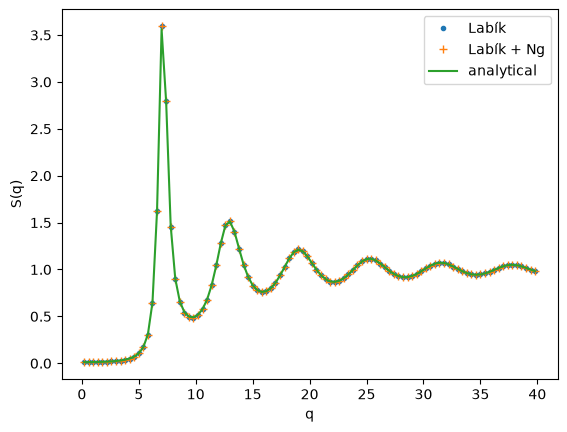

In [9]:
plt.plot(qgrid, Sq.Sq(qgrid)[0], '.', label='Labík')
plt.plot(qgrid, Sq.Sq(qgrid)[0], '+', label='Labík + Ng')
plt.plot(qgrid, hspy.Sq(qgrid)[0], label='analytical')
plt.xlabel('q')
plt.ylabel('S(q)')
plt.legend()
plt.show()

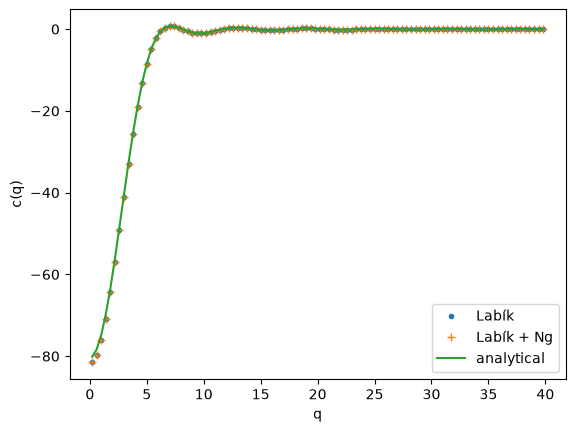

In [10]:
plt.plot(qgrid, Sq.Sq(qgrid)[1], '.', label='Labík')
plt.plot(qgrid, Sq.Sq(qgrid)[1], '+', label='Labík + Ng')
plt.plot(qgrid, hspy.Sq(qgrid)[1], label='analytical')
plt.xlabel('q')
plt.ylabel('c(q)')
plt.legend()
plt.show()

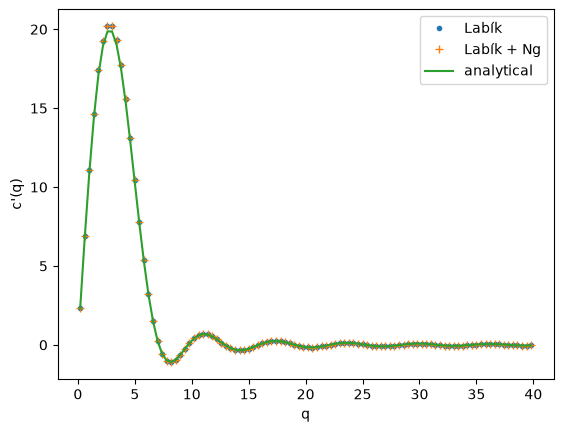

In [11]:
plt.plot(qgrid, Sq.dcq_dq(qgrid), '.', label='Labík')
plt.plot(qgrid, Sq.dcq_dq(qgrid), '+', label='Labík + Ng')
plt.plot(qgrid, hspy.dcq_dq(qgrid), label='analytical')
plt.xlabel('q')
plt.ylabel("c'(q)")
plt.legend()
plt.show()

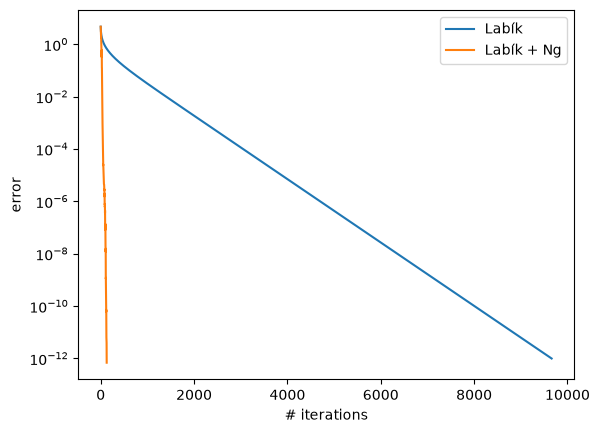

In [12]:
plt.plot(Sq.errlog, label='Labík')
plt.plot(Sq2.errlog, label='Labík + Ng')
plt.xlabel('# iterations')
plt.ylabel('error')
plt.yscale('log')
plt.legend()
plt.show()

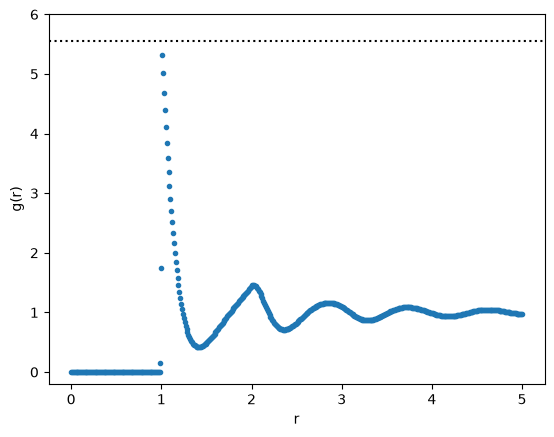

In [13]:
r = np.linspace(0,5,501)
phi = rho*np.pi/6.
plt.plot(r, Sq.gr(r),'.')
plt.axhline((1-1.5*phi+0.5*phi**3)/(1-phi)**4,linestyle='dotted',color='black')
plt.xlabel('r')
plt.ylabel('g(r)')
plt.ylim(-0.2,6)
plt.show()

In [14]:
from mctpy.structurefactors.oz import LJ, HNC

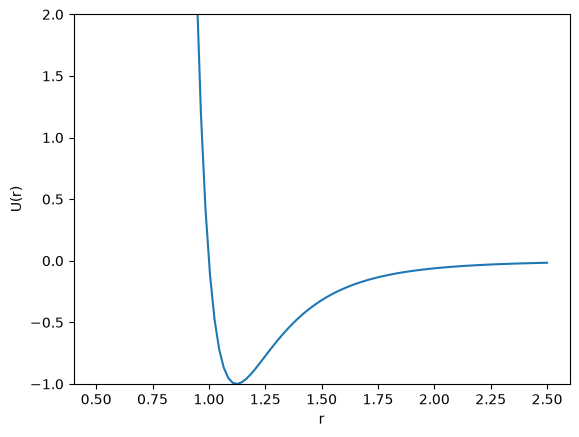

In [15]:
r = np.linspace(0.5,2.5,100)
plt.plot(r,LJ()(r))
plt.ylim(-1,2)
plt.xlabel('r')
plt.ylabel('U(r)')
plt.show()

In [16]:
Sq_LJ = mct.structurefactors.oz.Sq()
Gq0, Gr0 = None, None
for kT in tqdm([5.0,4.0,3.0,2.0,1.5,1.2]):
    Gr0, Gq0 = Sq_LJ.solve (closure=HNC(), potential=LJ(), rho=1.2, kT=kT, accuracy=1e-12, N=8192, use_ng=True, Gq0=Gq0, Gr0=Gr0)

  0%|          | 0/6 [00:00<?, ?it/s]

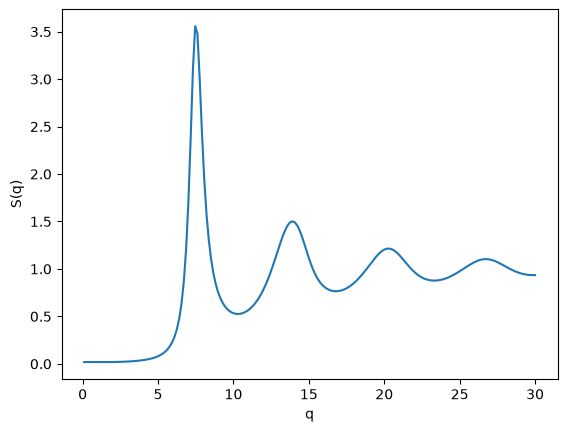

In [17]:
q = np.linspace(0.1,30,200)
plt.plot(q,Sq_LJ.Sq(q)[0])
plt.xlabel('q')
plt.ylabel('S(q)')
plt.show()